# Logistic regression: financial performance

Predict **financial performance (`success`)**: 0 Bust (ratio ≤1), 1 Moderate success (1<ratio<2.5), 2 Hit (ratio ≥2.5). Unknown finances remain unavailable.

Run All from this folder using **ds6001**. CSVs are read-only inputs; model choices and comparison versions are preserved.

Partner main-branch search settings and predictor exclusions are retained, adapted to the shared three-class target and precision/F1 objective. The dated binary snapshot is historical only.

## 1. Setup and controls
Edit the next cell, save, then Run All. Extra comparisons, coefficients, and full diagnostics are optional. Keep dates/folds consistent across models.

In [1]:
# Edit model/search settings here; shared goals live in project_policy.py.
from pathlib import Path
import sys
sys.path.insert(0, str(Path('../helpers').resolve()))
from project_policy import (CUTOFF_DATE, N_VALIDATION_SPLITS, RATING_SELECTION_METRIC,
    RATING_METRIC_GOALS, RATING_STRETCH_GOALS, SUCCESS_SELECTION_METRIC,
    SUCCESS_MIN_VALIDATION_PRECISION, SUCCESS_THRESHOLDS, BASE_THRESHOLD,
    OVERLAP_MAE_TOLERANCE, OVERLAP_HIT_F1_TOLERANCE, OVERLAP_MACRO_F1_TOLERANCE)
DATA_FILE = '../../data/model_data_success.csv'

MODEL_SETTINGS = {'C': 1.0, 'max_iter': 10000, 'random_state': 42, 'solver': 'saga'}
PARAM_GRID = {'classifier__C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
 'classifier__class_weight': [None, 'balanced'],
 'classifier__l1_ratio': [0.0, 0.5, 1.0]}
TUNING_METRIC = SUCCESS_SELECTION_METRIC
EXCLUDED_PREDICTORS = ['release_year',
 'n_genres',
 'backfill_unavailable',
 'franchise_prior_films_log1p',
 'dir_prior_rated_films_log1p',
 'dir_years_active_log1p',
 'dir_no_rating_history']
FEATURE_GROUPS_TO_COMPARE = ['Movie characteristics', '+ Director history', '+ Actor history', 'All features']
MIN_VALIDATION_PRECISION = SUCCESS_MIN_VALIDATION_PRECISION
THRESHOLDS = list(SUCCESS_THRESHOLDS)
OVERLAP_TRIMS = ['Drop genre count', 'Lean history', 'Lean history + director count']
SHOW_EXTRA_COMPARISONS = False
SHOW_COEFFICIENTS = False
SHOW_DIAGNOSTIC_DETAILS = False

In [2]:
from pathlib import Path
import sys
sys.path.insert(0, str(Path('../helpers').resolve()))
from model_workflow import (load_data, train_models, show_validation, show_results,
                            show_diagnostics_summary, save_report)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

data = load_data(DATA_FILE, 'success', CUTOFF_DATE, N_VALIDATION_SPLITS)

6,919 movies | 5,535 training / 1,384 later test | 40 available predictors


## 2. Model
The preprocessing and estimator are defined here. Missing-value filling, scaling, encoding and any polynomial/PCA transformations are fitted anew inside each training fold.

In [3]:
def make_model(columns):
    """Fresh preprocessing and classification for each feature set and split."""
    numeric = [column for column in data["NUMERIC_FEATURES"] if column in columns]
    categorical = [column for column in data["CATEGORICAL_FEATURES"] if column in columns]
    binary = [column for column in data["BINARY_FEATURES"] if column in columns]
    assert set(numeric + categorical + binary) == set(columns)
    preprocessing = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(drop=[{"us_certification":"R/NC-17", "release_month":"1"}[c] for c in categorical], handle_unknown="ignore", sparse_output=False)),
        ]), categorical),
        ("binary", "passthrough", binary),
    ])
    return Pipeline([
        ("preprocessor", preprocessing),
        ("classifier", LogisticRegression(**MODEL_SETTINGS)),
    ])

## 3. Validation and tuning
One call runs settings, feature-group and hit-threshold selection, then the bounded overlap review on the same expanding **training-only** folds. The later test period never selects candidates. These reused validation scores are exploratory selection estimates.

Shared implementation: [model_workflow.py](../helpers/model_workflow.py).

In [4]:
run = train_models(make_model, data, globals(), joint_search=False)
show_validation(run, details=SHOW_EXTRA_COMPARISONS)

Selected using three earlier-to-later folds inside training.


,Hit_precision,Hit_recall,Hit_F1,Macro_F1,Predictors,Hit threshold
0,0.7007,0.0961,0.1687,0.3436,25,0.65


Parameters: Original settings
Retained reference: trims did not justify a change.


## 4. Final results
Compare macro F1, moderate recall and hit precision/recall/F1 with the majority baseline. The matrix shows all three classes.

One main plot is shown here. All-model charts and residual/ROC/precision–recall plots are in [model visualizations](../../Data_visualization/model_visualizations.ipynb).

,Model,Split,Accuracy,Macro F1,Moderate recall,Hit precision,Hit recall,Hit F1
0,Dummy baseline,Test,0.3432,0.1703,0.0000,0.3432,1.0000,0.5110
1,Selected,Training,0.4262,0.3835,0.4412,0.6903,0.1198,0.2041
2,Selected,Test,0.4617,0.4259,0.4706,0.6467,0.2042,0.3104


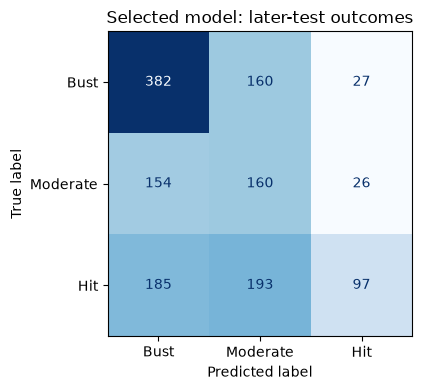

In [5]:
results = show_results(run, extra=SHOW_EXTRA_COMPARISONS, coefficients=SHOW_COEFFICIENTS)

## 5. Diagnostics
Review the short safeguards and before/after VIF table. Remaining correlations require cautious interpretation, not automatic deletion. Retrospective histories, missing finances and repeated test inspection limit generalization.

The [diagnostics guide](../DIAGNOSTICS.md) explains findings and next experiments. Full tables remain in `diagnostic_results`; the top switch displays them. The final line refreshes the generated comparison report without changing datasets.

Next experiments: compare class weights and hit thresholds inside training validation, tracking macro F1 and moderate recall alongside hit precision.

In [6]:
diagnostic_results = show_diagnostics_summary(run)
report_path = save_report(run, Path('logistic_regression.ipynb'))
print("Saved comparison report:", report_path)

,Check,Result
0,Programmed data/chronology safeguards,PASS; historical availability still unverified
1,Remaining overlap,0 inputs have VIF ≥10; coefficients need cauti...
2,Missing training inputs,runtime: 3 missing
3,Numerical fitting,"{'Estimator': 'LogisticRegression', 'Iteration..."
4,Generalization limits,"Later movies, missing finances and retrospecti..."


Overlap review: fewer redundant inputs; high VIF alone does not invalidate predictions.


,Stage,Predictors,Transformed inputs,VIF >=10,Maximum VIF,Removed
0,Before overlap trim,25,39.0,0.0,2.811,None
1,After overlap review,25,39.0,0.0,2.811,None


Next: compare further experiments only inside chronological training validation. Full technical tables are in diagnostic_results; set SHOW_DIAGNOSTIC_DETAILS=True to display them.


Saved comparison report: /Users/waltroou/DS-6021/DS_Final_Project/DS6021_Group2_FinalProject/Data_visualization/results/success/logistic_regression.json
